# Анализ BPE-токенизаторов GGPT (GeorgiaGPT)

Сравниваются Byte-level BPE-токенизаторы, обученные с нуля на грузинском
подкорпусе FineWeb2 (`kat_Geor`).

Исследуются два параметра:
- объём обучающей выборки: 10 000, 30 000 и 100 000 документов;
- размер словаря: 8192 и 16 384 токена.

Оценка проводится на фиксированной случайной подвыборке validation,
не использованной при обучении токенизаторов.

**Цель:** выбрать токенизатор, обеспечивающий разумный баланс между
компактностью представления текста и затратами на обучение GPT.

In [1]:
123

123

In [2]:

import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import regex
from IPython.display import display
from tokenizers import Tokenizer
from tqdm.auto import tqdm


def find_project_root(start: Path) -> Path:
    for directory in (start, *start.parents):
        if (directory / "dvc.yaml").is_file():
            return directory

    raise FileNotFoundError("GGPT project root not found")


ROOT = find_project_root(Path.cwd().resolve())

SOURCE_DIR = ROOT / "data/raw/fineweb2/data/kat_Geor/train"
SPLIT_DIR = ROOT / "data/splits/fineweb2/kat_Geor"
TOKENIZER_DIR = ROOT / "artifacts/tokenizer"

EVAL_DIR = ROOT / "data/interim/tokenizer/bpe_eval_sample"
EVAL_FILE = EVAL_DIR / "sample.parquet"
EVAL_MANIFEST = EVAL_DIR / "manifest.json"

REPORT_DIR = ROOT / "reports/tokenizer"
FIGURES_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", ROOT)


Project: /home/daneque/projects/GGPT


/home/daneque/miniconda/envs/ggpt/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:

EVAL_N_DOCS = 2000
EVAL_SEED = 20261019
ENCODE_BATCH_SIZE = 64

CANDIDATES = [
    {
        "name": "10k / 8192",
        "directory": "bpe_pilot_8192",
        "n_docs": 10_000,
        "vocab_size": 8192,
    },
    {
        "name": "10k / 16384",
        "directory": "bpe_10k_16384",
        "n_docs": 10_000,
        "vocab_size": 16384,
    },
    {
        "name": "30k / 8192",
        "directory": "bpe_30k_8192",
        "n_docs": 30_000,
        "vocab_size": 8192,
    },
    {
        "name": "30k / 16384",
        "directory": "bpe_30k_16384",
        "n_docs": 30_000,
        "vocab_size": 16384,
    },
    {
        "name": "100k / 8192",
        "directory": "bpe_100k_8192",
        "n_docs": 100_000,
        "vocab_size": 8192,
    },
    {
        "name": "100k / 16384",
        "directory": "bpe_100k_16384",
        "n_docs": 100_000,
        "vocab_size": 16384,
    },
]

SPECIAL_TOKENS = ["<|bos|>", "<|eos|>", "<|pad|>"]


In [4]:

split_manifest = json.loads(
    (SPLIT_DIR / "manifest.json").read_text(encoding="utf-8")
)

validation_indices = np.load(
    SPLIT_DIR / "validation_indices.npy",
    allow_pickle=False,
)

assert len(validation_indices) == 37_067
assert np.all(np.diff(validation_indices) > 0)
assert EVAL_N_DOCS <= len(validation_indices)

rng = np.random.default_rng(EVAL_SEED)

selected_indices = np.sort(
    rng.choice(
        validation_indices,
        size=EVAL_N_DOCS,
        replace=False,
    )
)

selected_sha256 = hashlib.sha256(
    selected_indices.tobytes()
).hexdigest()

assert np.all(np.isin(selected_indices, validation_indices))

print("Validation documents:", len(validation_indices))
print("Selected documents:", len(selected_indices))
print("Seed:", EVAL_SEED)
print("First selected indices:", selected_indices[:10])


Validation documents: 37067
Selected documents: 2000
Seed: 20261019
First selected indices: [ 4144  5010 11697 12418 13112 19425 21112 21440 23537 28987]


In [5]:

expected_manifest = {
    "source_revision": json.loads(
        (
            ROOT / "data/raw/fineweb2/download_manifest.json"
        ).read_text(encoding="utf-8")
    )["revision"],
    "evaluation_seed": EVAL_SEED,
    "evaluation_documents": EVAL_N_DOCS,
    "selected_indices_sha256": selected_sha256,
    "split_seed": split_manifest["seed"],
}

if EVAL_FILE.exists():
    if not EVAL_MANIFEST.exists():
        raise RuntimeError("Evaluation sample manifest is missing")

    saved_manifest = json.loads(
        EVAL_MANIFEST.read_text(encoding="utf-8")
    )

    for key, expected_value in expected_manifest.items():
        if saved_manifest.get(key) != expected_value:
            raise RuntimeError(
                f"Cached evaluation sample mismatch: {key}"
            )

    print("Loading cached evaluation sample")

else:
    if EVAL_MANIFEST.exists():
        raise RuntimeError("Incomplete evaluation sample")

    EVAL_DIR.mkdir(parents=True, exist_ok=True)

    records = []
    global_offset = 0

    source_files = split_manifest["source_files"]

    for file_info in tqdm(
        source_files,
        desc="Reading validation documents",
    ):
        path = SOURCE_DIR / file_info["path"]

        with pq.ParquetFile(path) as parquet:
            if parquet.metadata.num_rows != file_info["documents"]:
                raise RuntimeError(f"Source metadata mismatch: {path}")

            for rg in range(parquet.num_row_groups):
                row_count = parquet.metadata.row_group(rg).num_rows

                left = int(
                    np.searchsorted(selected_indices, global_offset)
                )
                right = int(
                    np.searchsorted(
                        selected_indices,
                        global_offset + row_count,
                    )
                )

                if left < right:
                    rows = selected_indices[left:right]
                    positions = rows - global_offset

                    table = parquet.read_row_group(
                        rg,
                        columns=["text"],
                    )

                    texts = table["text"].take(
                        pa.array(positions, type=pa.int64())
                    ).to_pylist()

                    records.extend(
                        {
                            "_global_row": int(row),
                            "text": text,
                        }
                        for row, text in zip(rows, texts)
                    )

                global_offset += row_count

    if global_offset != split_manifest["total_documents"]:
        raise RuntimeError("Incomplete source scan")

    if len(records) != EVAL_N_DOCS:
        raise RuntimeError("Incomplete validation extraction")

    result = pa.Table.from_pylist(
        records,
        schema=pa.schema([
            ("_global_row", pa.int64()),
            ("text", pa.string()),
        ]),
    )

    temporary_file = EVAL_DIR / "sample.parquet.partial"

    pq.write_table(
        result,
        temporary_file,
        compression="zstd",
    )

    temporary_file.replace(EVAL_FILE)

    EVAL_MANIFEST.write_text(
        json.dumps(
            expected_manifest,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    print("Evaluation sample saved:", EVAL_FILE)

eval_df = pq.read_table(EVAL_FILE).to_pandas()

assert len(eval_df) == EVAL_N_DOCS

np.testing.assert_array_equal(
    eval_df["_global_row"].to_numpy(),
    selected_indices,
)

assert eval_df["text"].notna().all()

print("Evaluation sample: OK")
display(eval_df.head(3).assign(
    text=lambda df: df["text"].str.slice(0, 160)
))


Reading validation documents: 100%|██████████| 2/2 [00:29<00:00, 14.59s/it]


Evaluation sample saved: /home/daneque/projects/GGPT/data/interim/tokenizer/bpe_eval_sample/sample.parquet
Evaluation sample: OK


,_global_row,text
0,4144,უკანასკნელი ექვსი თვის განმავლობაში ეროვნული ვ...
1,5010,"- ფაქტობრივად, ეს ჩემთვის პირველი ინტერვიუა. ჩ..."
2,11697,საქართველოს თავისუფალი სტილით მოჭიდავეთა ნაკრე...


In [6]:

WORD_PATTERN = regex.compile(r"\p{L}+")

texts = eval_df["text"].tolist()

document_stats = pd.DataFrame({
    "_global_row": eval_df["_global_row"].to_numpy(),
    "n_chars": np.array(
        [len(text) for text in texts],
        dtype=np.int64,
    ),
    "n_words": np.array(
        [len(WORD_PATTERN.findall(text)) for text in texts],
        dtype=np.int64,
    ),
})

print("Evaluation documents:", len(document_stats))
print("Total characters:", f"{document_stats['n_chars'].sum():,}")
print("Total words:", f"{document_stats['n_words'].sum():,}")

display(
    document_stats[["n_chars", "n_words"]]
    .describe(percentiles=[0.25, 0.5, 0.9, 0.99])
)


Evaluation documents: 2000
Total characters: 5,789,870
Total words: 691,640


,n_chars,n_words
count,2000.000000,2000.000000
mean,2894.935000,345.820000
std,4712.224508,577.484475
min,373.000000,46.000000
25%,869.000000,100.750000
50%,1552.500000,182.000000
90%,6102.200000,732.100000
99%,22233.860000,2712.160000
max,78652.000000,9220.000000


In [7]:

tokenizers = {}
manifests = []
selection_hashes = {}

for candidate in CANDIDATES:
    directory = TOKENIZER_DIR / candidate["directory"]

    tokenizer = Tokenizer.from_file(
        str(directory / "tokenizer.json")
    )

    manifest = json.loads(
        (directory / "manifest.json").read_text(
            encoding="utf-8"
        )
    )

    assert manifest["training_documents"] == candidate["n_docs"]
    assert manifest["actual_vocab_size"] == candidate["vocab_size"]
    assert manifest["sample_selection_seed"] == 2718

    for index, token in enumerate(SPECIAL_TOKENS):
        assert tokenizer.token_to_id(token) == index

    name = candidate["name"]
    n_docs = candidate["n_docs"]

    selection_hash = manifest["selected_indices_sha256"]

    if n_docs in selection_hashes:
        assert selection_hashes[n_docs] == selection_hash
    else:
        selection_hashes[n_docs] = selection_hash

    tokenizers[name] = tokenizer

    manifests.append({
        "model": name,
        "training_documents": n_docs,
        "vocab_size": tokenizer.get_vocab_size(),
        "training_seconds": manifest["training_seconds"],
        "peak_ram_mib": manifest["peak_process_rss_mb"],
        "tokenizers_version": manifest["library_version"],
    })

training_info = pd.DataFrame(manifests)

print("All tokenizers loaded: OK")
display(training_info)


All tokenizers loaded: OK


,model,training_documents,vocab_size,training_seconds,peak_ram_mib,tokenizers_version
0,10k / 8192,10000,8192,52.444,2441.3,0.23.3
1,10k / 16384,10000,16384,70.006,2435.4,0.23.3
2,30k / 8192,30000,8192,91.351,4387.2,0.23.3
3,30k / 16384,30000,16384,102.347,4385.4,0.23.3
4,100k / 8192,100000,8192,138.810,8558.3,0.23.3
5,100k / 16384,100000,16384,163.536,8573.7,0.23.3


In [8]:

rng = np.random.default_rng(12345)

roundtrip_indices = rng.choice(
    len(texts),
    size=min(50, len(texts)),
    replace=False,
)

roundtrip_texts = [
    texts[index]
    for index in roundtrip_indices
]

roundtrip_texts += [
    "",
    "გამარჯობა, საქართველო!",
    "ქართული ტექსტი\nმეორე ხაზი",
    "  გამარჯობა!  ",
    "Hello, world! Привет 🌍",
    "12345 !? \t\n",
]

for name, tokenizer in tqdm(
    tokenizers.items(),
    desc="Checking round-trip",
):
    for text in roundtrip_texts:
        encoding = tokenizer.encode(
            text,
            add_special_tokens=False,
        )

        restored = tokenizer.decode(
            encoding.ids,
            skip_special_tokens=False,
        )

        assert restored == text, (
            f"Round-trip failed for {name}: {text[:80]!r}"
        )

print(
    f"Round-trip: OK for {len(tokenizers)} tokenizers, "
    f"{len(roundtrip_texts)} texts each"
)


Checking round-trip: 100%|██████████| 6/6 [00:01<00:00,  4.17it/s]

Round-trip: OK for 6 tokenizers, 56 texts each


In [9]:

results = document_stats.copy()

for candidate in CANDIDATES:
    name = candidate["name"]
    tokenizer = tokenizers[name]

    lengths = []

    for start in tqdm(
        range(0, len(texts), ENCODE_BATCH_SIZE),
        desc=f"Encoding {name}",
    ):
        batch_texts = texts[
            start:start + ENCODE_BATCH_SIZE
        ]

        encoded = tokenizer.encode_batch(
            batch_texts,
            add_special_tokens=False,
        )

        lengths.extend(
            len(encoding.ids)
            for encoding in encoded
        )

    assert len(lengths) == len(texts)

    results[name] = np.asarray(
        lengths,
        dtype=np.int32,
    )

print("Tokenization completed")
display(results.head())


Encoding 100k / 16384: 100%|██████████| 32/32 [00:02<00:00, 12.40it/s]

Tokenization completed


,_global_row,n_chars,n_words,10k / 8192,10k / 16384,30k / 8192,30k / 16384,100k / 8192,100k / 16384
0,4144,2616,278,592,508,584,508,589,508
1,5010,26503,3382,7780,6940,7739,6888,7710,6871
2,11697,1849,212,583,505,583,507,583,505
3,12418,864,111,218,199,212,200,213,199
4,13112,1098,124,256,225,254,223,255,222


In [10]:

total_chars = int(results["n_chars"].sum())
total_words = int(results["n_words"].sum())

assert total_chars > 0
assert total_words > 0

summary_rows = []

for candidate in CANDIDATES:
    name = candidate["name"]
    lengths = results[name].to_numpy()

    total_tokens = int(lengths.sum())

    summary_rows.append({
        "model": name,
        "training_documents": candidate["n_docs"],
        "vocab_size": candidate["vocab_size"],
        "total_tokens": total_tokens,
        "tokens_per_1000_chars": (
            1000 * total_tokens / total_chars
        ),
        "tokens_per_word": (
            total_tokens / total_words
        ),
        "median_doc_tokens": float(np.median(lengths)),
        "p90_doc_tokens": float(np.quantile(lengths, 0.9)),
        "p99_doc_tokens": float(np.quantile(lengths, 0.99)),
    })

summary = (
    pd.DataFrame(summary_rows)
    .sort_values(
        ["training_documents", "vocab_size"]
    )
    .reset_index(drop=True)
)

display(
    summary.round({
        "tokens_per_1000_chars": 2,
        "tokens_per_word": 3,
        "median_doc_tokens": 1,
        "p90_doc_tokens": 1,
        "p99_doc_tokens": 1,
    })
)

summary.to_csv(
    REPORT_DIR / "bpe_comparison.csv",
    index=False,
)

print("Saved:", REPORT_DIR / "bpe_comparison.csv")


,model,training_documents,vocab_size,total_tokens,tokens_per_1000_chars,tokens_per_word,median_doc_tokens,p90_doc_tokens,p99_doc_tokens
0,10k / 8192,10000,8192,1555325,268.63,2.249,403.0,1652.3,5989.2
1,10k / 16384,10000,16384,1355505,234.12,1.960,347.0,1460.3,5263.1
2,30k / 8192,30000,8192,1552435,268.13,2.245,401.0,1654.6,5971.5
3,30k / 16384,30000,16384,1351457,233.42,1.954,346.5,1451.7,5256.0
4,100k / 8192,100000,8192,1552141,268.08,2.244,401.5,1654.2,5956.6
5,100k / 16384,100000,16384,1350354,233.23,1.952,345.5,1447.5,5257.0


Saved: /home/daneque/projects/GGPT/reports/tokenizer/bpe_comparison.csv


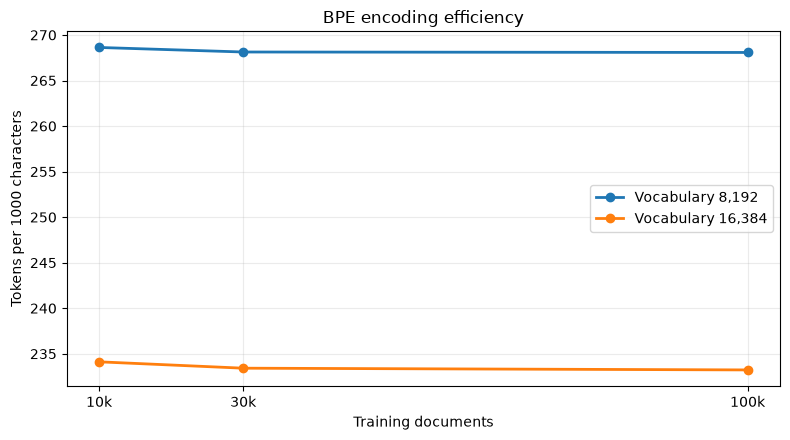

In [11]:

fig, ax = plt.subplots(figsize=(8, 4.5))

for vocab_size in [8192, 16384]:
    subset = summary[
        summary["vocab_size"] == vocab_size
    ].sort_values("training_documents")

    ax.plot(
        subset["training_documents"],
        subset["tokens_per_1000_chars"],
        marker="o",
        linewidth=2,
        label=f"Vocabulary {vocab_size:,}",
    )

ax.set_xticks([10_000, 30_000, 100_000])
ax.set_xticklabels(["10k", "30k", "100k"])

ax.set_xlabel("Training documents")
ax.set_ylabel("Tokens per 1000 characters")
ax.set_title("BPE encoding efficiency")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "bpe_efficiency.png",
    dpi=170,
    bbox_inches="tight",
)

plt.show()


,training_documents,token_savings_pct
0,10000,12.85
1,30000,12.95
2,100000,13.00


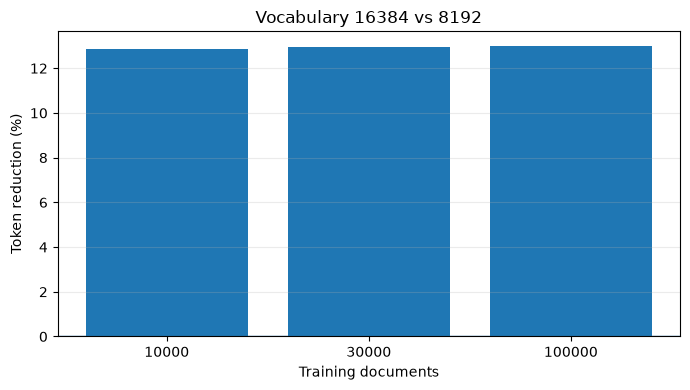

In [12]:

savings_rows = []

for n_docs in [10_000, 30_000, 100_000]:
    smaller = summary[
        (summary["training_documents"] == n_docs)
        & (summary["vocab_size"] == 8192)
    ].iloc[0]

    larger = summary[
        (summary["training_documents"] == n_docs)
        & (summary["vocab_size"] == 16384)
    ].iloc[0]

    savings = 100 * (
        smaller["total_tokens"] - larger["total_tokens"]
    ) / smaller["total_tokens"]

    savings_rows.append({
        "training_documents": n_docs,
        "token_savings_pct": savings,
    })

savings_df = pd.DataFrame(savings_rows)

display(savings_df.round(2))

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    savings_df["training_documents"].astype(str),
    savings_df["token_savings_pct"],
)

ax.axhline(0, linewidth=1)
ax.set_xlabel("Training documents")
ax.set_ylabel("Token reduction (%)")
ax.set_title("Vocabulary 16384 vs 8192")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "vocabulary_savings.png",
    dpi=170,
    bbox_inches="tight",
)

plt.show()


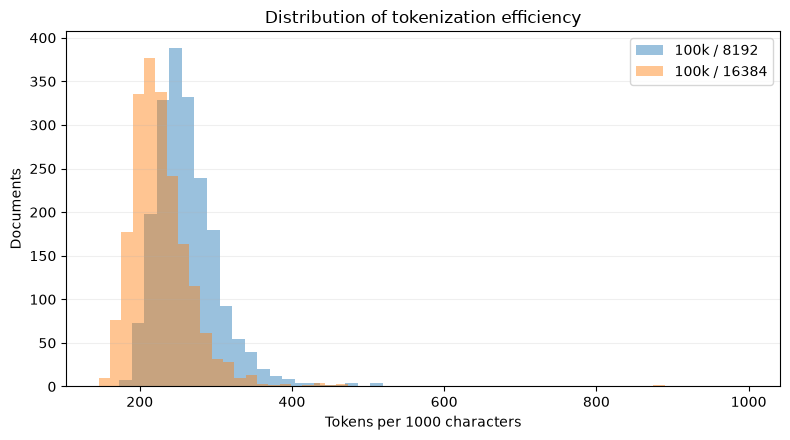

In [13]:

fig, ax = plt.subplots(figsize=(8, 4.5))

chars = results["n_chars"].replace(0, np.nan)

for name in ["100k / 8192", "100k / 16384"]:
    normalized = (
        1000 * results[name] / chars
    ).dropna()

    ax.hist(
        normalized,
        bins=50,
        alpha=0.45,
        label=name,
    )

ax.set_xlabel("Tokens per 1000 characters")
ax.set_ylabel("Documents")
ax.set_title("Distribution of tokenization efficiency")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "bpe_distribution.png",
    dpi=170,
    bbox_inches="tight",
)

plt.show()


In [14]:

examples = [
    "გამარჯობა, საქართველო!",
    "მე მიყვარს ქართული ენა.",
    "საქართველო მდებარეობს კავკასიის რეგიონში.",
    "ქართული ენა მდიდარია ისტორიული და კულტურული ტრადიციებით.",
    "თბილისი საქართველოს დედაქალაქია.",
]

example_rows = []

for text in examples:
    for name in ["100k / 8192", "100k / 16384"]:
        encoding = tokenizers[name].encode(
            text,
            add_special_tokens=False,
        )

        example_rows.append({
            "text": text,
            "tokenizer": name,
            "n_tokens": len(encoding.ids),
            "internal_tokens": " | ".join(encoding.tokens),
        })

examples_df = pd.DataFrame(example_rows)

display(examples_df)


,text,tokenizer,n_tokens,internal_tokens
0,"გამარჯობა, საქართველო!",100k / 8192,6,"áĥĴáĥĲáĥĽ | áĥĲáĥłáĥ¯ | áĥĿáĥĳáĥĲ | , | Ġáĥ¡áĥ..."
1,"გამარჯობა, საქართველო!",100k / 16384,5,"áĥĴáĥĲáĥĽáĥĲáĥłáĥ¯ | áĥĿáĥĳáĥĲ | , | Ġáĥ¡áĥĲáĥ..."
2,მე მიყვარს ქართული ენა.,100k / 8192,5,áĥĽáĥĶ | ĠáĥĽáĥĺáĥ§áĥķáĥĲáĥłáĥ¡ | Ġáĥ¥áĥĲáĥłáĥ...
3,მე მიყვარს ქართული ენა.,100k / 16384,5,áĥĽáĥĶ | ĠáĥĽáĥĺáĥ§áĥķáĥĲáĥłáĥ¡ | Ġáĥ¥áĥĲáĥłáĥ...
4,საქართველო მდებარეობს კავკასიის რეგიონში.,100k / 8192,6,áĥ¡áĥĲáĥ¥áĥĲáĥłáĥĹáĥķáĥĶáĥļáĥĿ | ĠáĥĽáĥĵáĥĶáĥĳ...
5,საქართველო მდებარეობს კავკასიის რეგიონში.,100k / 16384,5,áĥ¡áĥĲáĥ¥áĥĲáĥłáĥĹáĥķáĥĶáĥļáĥĿ | ĠáĥĽáĥĵáĥĶáĥĳ...
6,ქართული ენა მდიდარია ისტორიული და კულტურული ტრ...,100k / 8192,10,áĥ¥áĥĲáĥłáĥĹáĥ£áĥļáĥĺ | ĠáĥĶáĥľáĥĲ | ĠáĥĽáĥĵáĥ...
7,ქართული ენა მდიდარია ისტორიული და კულტურული ტრ...,100k / 16384,10,áĥ¥áĥĲáĥłáĥĹáĥ£áĥļáĥĺ | ĠáĥĶáĥľáĥĲ | ĠáĥĽáĥĵáĥ...
8,თბილისი საქართველოს დედაქალაქია.,100k / 8192,5,áĥĹáĥĳáĥĺáĥļáĥĺáĥ¡áĥĺ | Ġáĥ¡áĥĲáĥ¥áĥĲáĥłáĥĹáĥķ...
9,თბილისი საქართველოს დედაქალაქია.,100k / 16384,5,áĥĹáĥĳáĥĺáĥļáĥĺáĥ¡áĥĺ | Ġáĥ¡áĥĲáĥ¥áĥĲáĥłáĥĹáĥķ...


In [15]:

cost_rows = []

for d_model in [256, 384, 512]:
    extra_parameters = (16_384 - 8192) * d_model

    cost_rows.append({
        "d_model": d_model,
        "extra_parameters": extra_parameters,
        "extra_millions": extra_parameters / 1e6,
        "extra_fp32_weights_mib": (
            extra_parameters * 4 / 1024**2
        ),
    })

display(pd.DataFrame(cost_rows).round(2))


,d_model,extra_parameters,extra_millions,extra_fp32_weights_mib
0,256,2097152,2.10,8.0
1,384,3145728,3.15,12.0
2,512,4194304,4.19,16.0


In [16]:

summary_path = REPORT_DIR / "bpe_comparison.csv"
savings_path = REPORT_DIR / "vocabulary_savings.csv"

summary.to_csv(summary_path, index=False)
savings_df.to_csv(savings_path, index=False)

print("Saved files:")
print(summary_path)
print(savings_path)

print("\nModels ordered by tokenization efficiency:")

display(
    summary[
        [
            "model",
            "tokens_per_1000_chars",
            "tokens_per_word",
            "total_tokens",
        ]
    ].sort_values("tokens_per_1000_chars").round(3)
)


Saved files:
/home/daneque/projects/GGPT/reports/tokenizer/bpe_comparison.csv
/home/daneque/projects/GGPT/reports/tokenizer/vocabulary_savings.csv

Models ordered by tokenization efficiency:


,model,tokens_per_1000_chars,tokens_per_word,total_tokens
5,100k / 16384,233.227,1.952,1350354
3,30k / 16384,233.418,1.954,1351457
1,10k / 16384,234.117,1.960,1355505
4,100k / 8192,268.079,2.244,1552141
2,30k / 8192,268.130,2.245,1552435
0,10k / 8192,268.629,2.249,1555325


По результатам сравнения шести BPE-токенизаторов установлено, что увеличение обучающей выборки с 10 до 100 тысяч документов даёт незначительное улучшение эффективности токенизации (менее 0,4%). Гораздо заметнее влияет размер словаря: переход от 8192 к 16 384 токенам сокращает длину кодированных последовательностей примерно на 13%.

Для GeorgiaGPT выбран Byte-level BPE со словарём 16 384 токена, обученный на 100 000 документах. Он показал наилучшую эффективность кодирования, хотя увеличение словаря потребует дополнительных вычислений и параметров модели.